In [6]:
#Cell 1: Setup
import sys
from pathlib import Path

# Make "src" importable when the notebook runs from the notebooks/ folder
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))

import hashlib
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.model_selection import train_test_split

from src.config import CLASSES, DATA_RAW, FIG_DIR, SEED, SPLITS_DIR

random.seed(SEED)
np.random.seed(SEED)

print("Project root:", ROOT)
print("Data folder: ", DATA_RAW)

Project root: E:\UBC\UBC TERM 1\ENGR 501- Deep Learning (and Reinforcement Learning) for Engineers\PROJECT\potato-disease-cnn
Data folder:  E:\UBC\UBC TERM 1\ENGR 501- Deep Learning (and Reinforcement Learning) for Engineers\PROJECT\potato-disease-cnn\data\raw


In [8]:
#Cell 2: Check the class folders
for c in CLASSES:
    folder = DATA_RAW / c
    n = len(list(folder.glob("*"))) if folder.exists() else 0
    print(f"{c:25s} exists={folder.exists()}  files={n}")

Potato___Early_blight     exists=True  files=1000
Potato___Late_blight      exists=True  files=1000
Potato___healthy          exists=True  files=152


In [10]:
#Cell 3: Build a table of all images
EXTS = {".jpg", ".jpeg", ".png"}

rows = []
for label, c in enumerate(CLASSES):
    for p in sorted((DATA_RAW / c).iterdir()):
        if p.suffix.lower() in EXTS:
            rows.append({
                "path": p.relative_to(ROOT).as_posix(),
                "class_name": c,
                "label": label,
            })

df = pd.DataFrame(rows)
print("Total images:", len(df))
df.head()

Total images: 2152


,path,class_name,label
0,data/raw/Potato___Early_blight/001187a0-57ab-4...,Potato___Early_blight,0
1,data/raw/Potato___Early_blight/002a55fb-7a3d-4...,Potato___Early_blight,0
2,data/raw/Potato___Early_blight/009c8c31-f22d-4...,Potato___Early_blight,0
3,data/raw/Potato___Early_blight/00d8f10f-5038-4...,Potato___Early_blight,0
4,data/raw/Potato___Early_blight/0182e991-97f0-4...,Potato___Early_blight,0


In [12]:
#Cell 4: Remove corrupt images and exact duplicates
def check_image(rel_path):
    """Return (is_valid, md5_hash) for one image."""
    full = ROOT / rel_path
    try:
        with Image.open(full) as img:
            img.verify()
        ok = True
    except Exception:
        ok = False
    md5 = hashlib.md5(full.read_bytes()).hexdigest()
    return ok, md5

df[["is_valid", "md5"]] = df["path"].apply(lambda p: pd.Series(check_image(p)))

print("Corrupt images:       ", (~df["is_valid"]).sum())
print("Exact duplicate files:", df.duplicated("md5").sum())

df = df[df["is_valid"]].drop_duplicates("md5").reset_index(drop=True)
df = df.drop(columns=["is_valid"])
print("Clean images:         ", len(df))

Corrupt images:        0
Exact duplicate files: 0
Clean images:          2152


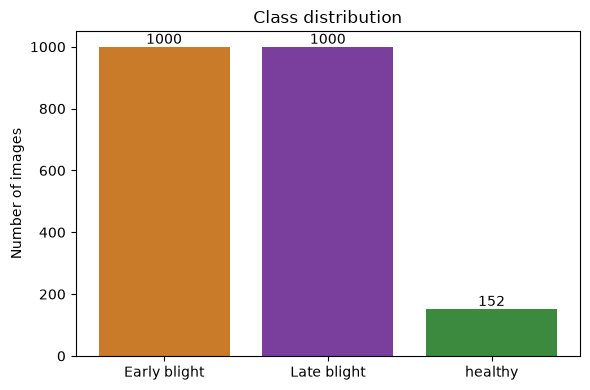

In [14]:
#Cell 5: Class distribution plot
counts = df["class_name"].value_counts().reindex(CLASSES)
short = [c.replace("Potato___", "").replace("_", " ") for c in CLASSES]

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(short, counts.values, color=["#c97b2a", "#7a3e9d", "#3b8a3e"])
for i, v in enumerate(counts.values):
    ax.text(i, v + 10, str(v), ha="center")
ax.set_ylabel("Number of images")
ax.set_title("Class distribution")
plt.tight_layout()
plt.savefig(FIG_DIR / "class_distribution.png", dpi=200)
plt.show()

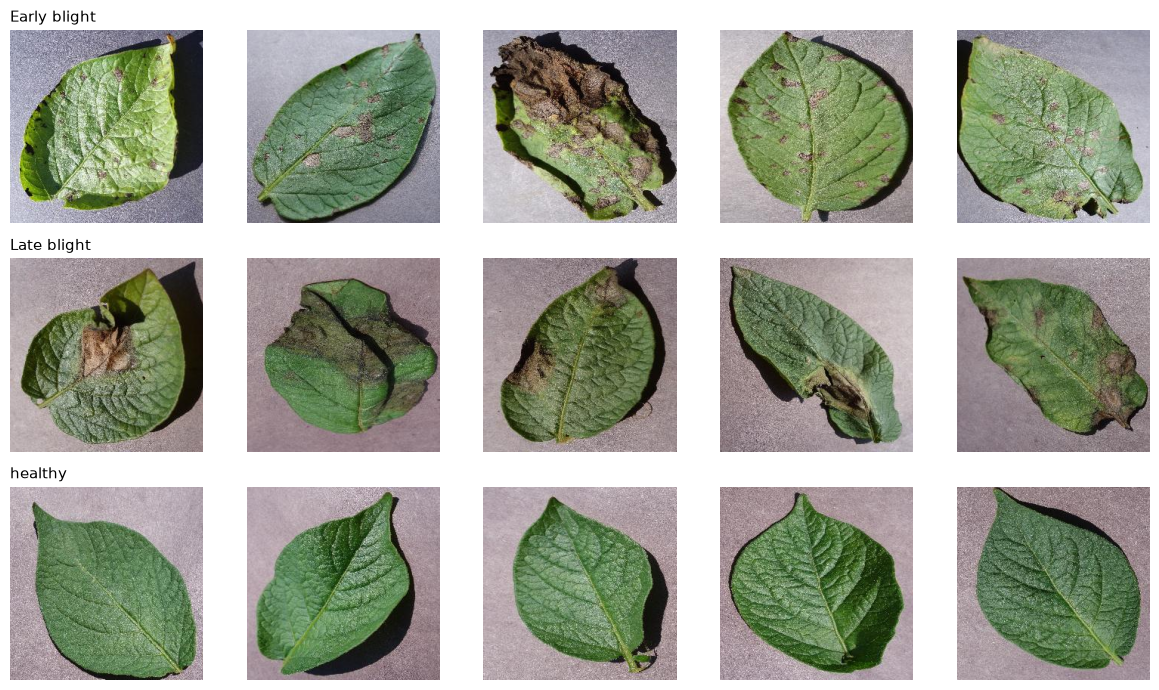

In [15]:
#Cell 6: Show sample images from each class
fig, axes = plt.subplots(len(CLASSES), 5, figsize=(12, 7))

for r, c in enumerate(CLASSES):
    sample = df[df["class_name"] == c].sample(5, random_state=SEED)
    for k, rel in enumerate(sample["path"]):
        axes[r, k].imshow(Image.open(ROOT / rel))
        axes[r, k].axis("off")
    axes[r, 0].set_title(short[r], loc="left", fontsize=11)

plt.tight_layout()
plt.savefig(FIG_DIR / "sample_images.png", dpi=200)
plt.show()

In [17]:
#Cell 7: Check image sizes
sizes = [Image.open(ROOT / p).size for p in df["path"].sample(200, random_state=SEED)]
pd.Series(sizes).value_counts()

(256, 256)    200
Name: count, dtype: int64

In [19]:
#Cell 8: Split the data into train / validation / test
train_df, temp_df = train_test_split(
    df, test_size=0.30, stratify=df["label"], random_state=SEED
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED
)

summary = pd.DataFrame({
    "train": train_df["class_name"].value_counts(),
    "val": val_df["class_name"].value_counts(),
    "test": test_df["class_name"].value_counts(),
}).reindex(CLASSES)
summary.loc["total"] = summary.sum()
summary

,train,val,test
class_name,,,
Potato___Early_blight,700,150,150
Potato___Late_blight,700,150,150
Potato___healthy,106,23,23
total,1506,323,323


In [20]:
#Cell 9: Verify no overlap and save the split
train_set = set(train_df["path"])
val_set = set(val_df["path"])
test_set = set(test_df["path"])

assert not (train_set & val_set), "train/val overlap!"
assert not (train_set & test_set), "train/test overlap!"
assert not (val_set & test_set), "val/test overlap!"
print("No overlap between splits ✓")

cols = ["path", "class_name", "label"]
train_df[cols].to_csv(SPLITS_DIR / "train.csv", index=False)
val_df[cols].to_csv(SPLITS_DIR / "val.csv", index=False)
test_df[cols].to_csv(SPLITS_DIR / "test.csv", index=False)
summary.to_csv(SPLITS_DIR / "split_summary.csv")

print("Saved to", SPLITS_DIR)

No overlap between splits ✓
Saved to E:\UBC\UBC TERM 1\ENGR 501- Deep Learning (and Reinforcement Learning) for Engineers\PROJECT\potato-disease-cnn\data\splits
